# **Installing all the relavant libraries**

In [1]:
pip install pandas numpy scikit-learn

Note: you may need to restart the kernel to use updated packages.


**Experiment 1 : Data Analysis and Imputation**

In [2]:
import numpy as np
import pandas as pd
from sklearn.impute import KNNImputer, SimpleImputer

# ==========================================
# STEP 1: Simulate a Civil Engineering Dataset
# ==========================================
# Let's create a concrete test dataset with missing values (NaN)
data = {
    "Concrete_Age_Days": [7, 7, 14, 28, 28, 28, 56, np.nan, 90, 90],
    "Water_Cement_Ratio": [0.45, 0.45, 0.40, np.nan, 0.50, 0.42, 0.38, 0.45, np.nan, 0.35],
    "Slump_mm": [80, np.nan, 90, 75, 110, 85, np.nan, 95, 60, 50],
    "Compressive_Strength_MPa": [22.4, 21.8, 30.5, 41.2, np.nan, 43.8, 52.1, 38.0, 55.4, 58.2],
}

df = pd.DataFrame(data)
print("--- Original Civil Engineering Dataset ---")
print(df)
print("\n" + "=" * 50 + "\n")

# ==========================================
# STEP 2: Find Missing Values
# ==========================================
print("--- Finding Missing Values ---")
# Count total missing values per column
missing_count = df.isnull().sum()

# Calculate the percentage of missing data per column
missing_percentage = (df.isnull().sum() / len(df)) * 100

# Combine into a summary dataframe
missing_summary = pd.DataFrame(
    {"Missing Count": missing_count, "Percentage (%)": missing_percentage}
)
print(missing_summary)
print("\n" + "=" * 50 + "\n")

# ==========================================
# STEP 3: Imputation Method A - Statistical Mean/Median
# ==========================================
# Best for independent variables where values cluster closely around an average.
print("--- Method A: Imputation using Mean/Median (Pandas) ---")

df_mean_imputed = df.copy()

# Impute 'Concrete_Age_Days' with the median (since days are discrete intervals)
df_mean_imputed["Concrete_Age_Days"] = df_mean_imputed["Concrete_Age_Days"].fillna(
    df_mean_imputed["Concrete_Age_Days"].median()
)

# Impute 'Compressive_Strength_MPa' with the column mean
df_mean_imputed["Compressive_Strength_MPa"] = df_mean_imputed[
    "Compressive_Strength_MPa"
].fillna(df_mean_imputed["Compressive_Strength_MPa"].mean())

print("Dataset after filling Age (Median) and Strength (Mean):")
print(df_mean_imputed.round(2))
print("\n" + "=" * 50 + "\n")

# ==========================================
# STEP 4: Imputation Method B - Advanced KNN (K-Nearest Neighbors)
# ==========================================
# Best for civil data where properties are closely linked (e.g., Slump vs Water-Cement Ratio).
# KNN looks at 'K' similar rows to predict and fill the missing value.
print("--- Method B: Advanced Imputation using KNN (Scikit-Learn) ---")

# Initialize KNN Imputer (using 2 nearest neighboring samples to weigh the missing values)
knn_imputer = KNNImputer(n_neighbors=2)

# Fit and transform the original dataframe
imputed_array = knn_imputer.fit_transform(df)

# Convert the resulting numpy array back into a readable Pandas DataFrame
df_knn_imputed = pd.DataFrame(imputed_array, columns=df.columns)

print("Dataset after KNN Imputation (All missing values solved dynamically):")
print(df_knn_imputed.round(2))


--- Original Civil Engineering Dataset ---
   Concrete_Age_Days  Water_Cement_Ratio  Slump_mm  Compressive_Strength_MPa
0                7.0                0.45      80.0                      22.4
1                7.0                0.45       NaN                      21.8
2               14.0                0.40      90.0                      30.5
3               28.0                 NaN      75.0                      41.2
4               28.0                0.50     110.0                       NaN
5               28.0                0.42      85.0                      43.8
6               56.0                0.38       NaN                      52.1
7                NaN                0.45      95.0                      38.0
8               90.0                 NaN      60.0                      55.4
9               90.0                0.35      50.0                      58.2


--- Finding Missing Values ---
                          Missing Count  Percentage (%)
Concrete_Age_Days    

**Experiment 2: Outlier Detection.**
In civil engineering datasets, outliers can represent two things: experimental anomalies (such as a faulty sensor crack-gauge reading or human data-entry typos) or true structural anomalies (like a bridge beam under extreme stress). Recognizing and filtering these data points is critical before deploying structural or geotechnical safety models.
We will use two industry-standard approaches: IQR (Interquartile Range) for univariate metrics and Isolation Forest (a machine learning model) for complex, multi-variable outlier profiling.

In [3]:
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest

# ==========================================
# STEP 1: Load/Simulate Civil Case Study Data
# ==========================================
# We simulate structural health monitoring sensor data tracking concrete beam strain.
np.random.seed(42)
normal_strain = np.random.normal(loc=150, scale=15, size=45)  # Normal microstrain readings

# Intentionally introduce structural or sensor outliers (extreme/anomalous measurements)
outliers = np.array([450.0, 12.0, 500.0, -90.0, 162.0])

all_readings = np.concatenate([normal_strain, outliers])

# Build our working Case Study DataFrame
df = pd.DataFrame(
    {"Sensor_ID": range(1, 51), "Microstrain_μϵ": np.round(all_readings, 2)}
)

print("--- First 5 Rows of Case Study Data ---")
print(df.head())
print(f"\nTotal rows to analyze: {len(df)}")
print("\n" + "=" * 50 + "\n")

# ==========================================
# STEP 2: Statistical Method - IQR (Interquartile Range)
# ==========================================
# Ideal for individual key variables like concrete slump or maximum deflection.
print("--- Method A: Outlier Detection via IQR ---")

# Compute Quartiles
Q1 = df["Microstrain_μϵ"].quantile(0.25)
Q3 = df["Microstrain_μϵ"].quantile(0.75)
IQR = Q3 - Q1

# Define Upper and Lower Fences
lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

print(f"IQR: {IQR:.2f} | Lower Limit: {lower_fence:.2f} | Upper Limit: {upper_fence:.2f}")

# Extract Outliers using IQR
iqr_outliers = df[
    (df["Microstrain_μϵ"] < lower_fence) | (df["Microstrain_μϵ"] > upper_fence)
]

print(f"\n[IQR Method] Identified {len(iqr_outliers)} Outliers:")
print(iqr_outliers)
print("\n" + "=" * 50 + "\n")

# ==========================================
# STEP 3: Machine Learning Method - Isolation Forest
# ==========================================
# Perfect for multidimensional matrix sweeps or highly irregular engineering datasets.
print("--- Method B: Outlier Detection via Isolation Forest ---")

# Reshape data for scikit-learn compatibility
X = df[["Microstrain_μϵ"]].values

# Initialize Isolation Forest. contamination=0.10 assumes roughly 10% of records are outliers.
iso_forest = IsolationForest(contamination=0.10, random_state=42)

# Fit model and predict (-1 signifies an outlier, 1 signifies normal data)
df["Anomaly_Score"] = iso_forest.fit_predict(X)

# Filter out the detected anomalies
ml_outliers = df[df["Anomaly_Score"] == -1]

print(f"[Isolation Forest] Identified {len(ml_outliers)} Outliers:")
print(ml_outliers[["Sensor_ID", "Microstrain_μϵ"]])
print("\n" + "=" * 50 + "\n")

# ==========================================
# STEP 4: Strategy to Deal with Outliers
# ==========================================
print("--- Post-Detection Action Summary ---")
# Drop the IQR outliers to generate a clean engineering dataset baseline
df_cleaned_iqr = df[
    (df["Microstrain_μϵ"] >= lower_fence) & (df["Microstrain_μϵ"] <= upper_fence)
]
print(f"Original dataset rows: {len(df)}")
print(f"Cleaned dataset rows (Outliers removed): {len(df_cleaned_iqr)}")


--- First 5 Rows of Case Study Data ---
   Sensor_ID  Microstrain_μϵ
0          1          157.45
1          2          147.93
2          3          159.72
3          4          172.85
4          5          146.49

Total rows to analyze: 50


--- Method A: Outlier Detection via IQR ---
IQR: 21.80 | Lower Limit: 102.51 | Upper Limit: 189.69

[IQR Method] Identified 4 Outliers:
    Sensor_ID  Microstrain_μϵ
45         46           450.0
46         47            12.0
47         48           500.0
48         49           -90.0


--- Method B: Outlier Detection via Isolation Forest ---
[Isolation Forest] Identified 5 Outliers:
    Sensor_ID  Microstrain_μϵ
31         32          177.78
45         46          450.00
46         47           12.00
47         48          500.00
48         49          -90.00


--- Post-Detection Action Summary ---
Original dataset rows: 50
Cleaned dataset rows (Outliers removed): 46




1. IQR Boxplot Method: This maps mathematically to standard boxplot rules. Anything 1.5 times past the middle 50% boundary is flagged. It isolates the manual reading errors (like the negative -90.0 value which might mean a reversed wire hookup or the 500.0 value which indicates a loose connection).

2.   Isolation Forest: This algorithm isolates anomalies instead of profiling normal points. It runs efficiently on massive infrastructure arrays (e.g., dams monitoring hundreds of piezometers or geo-sensors simultaneously).



**Experiment 3: Handling Duplicate Data.**

In civil engineering databases—such as material tracking ledgers, traffic sensor logs, or concrete batch plant receipts—duplicate data frequently slips in. This happens due to network lag re-sending sensor packets, human errors during manual survey entries, or joining mismatched structural inspection spreadsheets. Leaving duplicates in can falsely skew structural safety averages and artificially shrink data variance.
We will use Pandas to profile, locate, extract, and cleanly remove duplicate records using different engineering rules (e.g., dropping absolute row matches vs. dropping entries based on a unique identifier like a structural asset ID).

In [4]:
import pandas as pd

# ==========================================
# STEP 1: Simulate a Civil Asset Management Dataset
# ==========================================
# We have an inspection log tracking structural defects in concrete bridges.
data = {
    "Bridge_ID": ["BR-01", "BR-02", "BR-03", "BR-01", "BR-02", "BR-04", "BR-01"],
    "Inspection_Date": ["2026-10-01", "2026-10-02", "2026-10-03", "2026-10-01", "2026-10-02", "2026-10-05", "2026-10-01"],
    "Crack_Width_mm": [2.5, 0.8, 4.1, 2.5, 1.2, 0.5, 2.5],
    "Deflection_mm": [12.4, 4.2, 22.1, 12.4, 4.5, 2.1, 12.4]
}

df = pd.DataFrame(data)
print("--- Original Civil Inspection Dataset ---")
print(df)
print(f"\nTotal Rows: {len(df)}")
print("\n" + "=" * 50 + "\n")

# ==========================================
# STEP 2: Find and Inspect Duplicate Rows
# ==========================================
print("--- Method A: Identifying Duplicate Records ---")

# Check if individual rows are completely identical to a previous row
duplicate_mask = df.duplicated(keep='first')
# keep='first' marks the first occurrence as False (Normal) and later copies as True (Duplicate)

# Count the total number of exact duplicate entries
total_duplicates = duplicate_mask.sum()
print(f"Total exact duplicate rows found: {total_duplicates}")

# Extract and view the actual duplicate rows for engineering verification
duplicate_rows = df[duplicate_mask]
print("\nIsolated Duplicate Records:")
print(duplicate_rows)
print("\n" + "=" * 50 + "\n")

# ==========================================
# STEP 3: Remove Exact Duplicates (Row-Wise)
# ==========================================
print("--- Method B: Dropping Absolute Row Duplicates ---")

# drop_duplicates() removes rows where EVERY single column value matches perfectly.
# We keep='first' to preserve the original entry.
df_cleaned_exact = df.drop_duplicates(keep='first')

print("Dataset after dropping exact row duplicates:")
print(df_cleaned_exact)
print(f"\nRemaining Rows: {len(df_cleaned_exact)}")
print("\n" + "=" * 50 + "\n")

# ==========================================
# STEP 4: Remove Specific Duplicates based on Primary Keys
# ==========================================
# Look closely at Row 1 and Row 4 for "BR-02".
# The crack sizes changed from 0.8mm to 1.2mm, but it's the same bridge inspected on the same day.
# In engineering, we may only want the latest entry or want to clear telemetry system bugs.

print("--- Method C: Handling Key-Based Duplicates (Bridge ID + Date) ---")

# Drop duplicates targeting only specific subset columns.
# keep='last' tells Python to preserve the most recent/updated update in the logs.
df_cleaned_subset = df.drop_duplicates(subset=["Bridge_ID", "Inspection_Date"], keep='last')

print("Dataset keeping only the LAST record for a specific Bridge on a specific Date:")
print(df_cleaned_subset)
print(f"\nFinal Tailored Dataset Rows: {len(df_cleaned_subset)}")


--- Original Civil Inspection Dataset ---
  Bridge_ID Inspection_Date  Crack_Width_mm  Deflection_mm
0     BR-01      2026-10-01             2.5           12.4
1     BR-02      2026-10-02             0.8            4.2
2     BR-03      2026-10-03             4.1           22.1
3     BR-01      2026-10-01             2.5           12.4
4     BR-02      2026-10-02             1.2            4.5
5     BR-04      2026-10-05             0.5            2.1
6     BR-01      2026-10-01             2.5           12.4

Total Rows: 7


--- Method A: Identifying Duplicate Records ---
Total exact duplicate rows found: 2

Isolated Duplicate Records:
  Bridge_ID Inspection_Date  Crack_Width_mm  Deflection_mm
3     BR-01      2026-10-01             2.5           12.4
6     BR-01      2026-10-01             2.5           12.4


--- Method B: Dropping Absolute Row Duplicates ---
Dataset after dropping exact row duplicates:
  Bridge_ID Inspection_Date  Crack_Width_mm  Deflection_mm
0     BR-01      2026-


1. df.duplicated() Verification: Before purging any records, civil engineers must verify why rows match. For example, if two different structural sensors read exactly 12.4 mm deflection, they are not necessarily duplicates unless they share the same timestamp and sensor ID.
2.   keep='first' vs keep='last' Strategy: If a data-entry terminal bugs out and submits the same batch ticket three times, keeping the first one is ideal. However, if a structural field team submits a corrected measurement for the same bridge on the same day, keeping the last record ensures you utilize the revised engineering metric.



**Experiment 4: Perform data normalization**
In civil engineering datasets, input variables often use entirely different units and measurement scales. For example, concrete Elastic Modulus can range in the tens of thousands of megapascals (20,000–40,000 MPa20,000\text{–}40,000\text{ MPa}), while Water-Cement Ratio ranges as a tiny decimal (0.30–0.600.30\text{–}0.60). If you feed these unscaled features into machine learning models (like neural networks or distance-based algorithms), the model will mistakenly assume that the feature with the massive numbers is more important.

To prevent this bias, we use data normalisation techniques to bring all engineering variables onto an equal scale. We will use two industry-standard methods from Scikit-Learn: Min-Max Normalisation and Standardisation (Z-score Scaling).

1. Min-Max Scaling: Notice how the raw values are reshaped completely. The highest compressive strength (55.2 MPa) scales cleanly to exactly 1.000, and the lowest (28.4 MPa) maps to 0.000. This is highly predictable and visually simple to evaluate.
2. Standardisation (Z-score): This translates your engineering numbers into "standard deviations away from the project average." A value of 1.34 means that concrete mix has a aggregate quantity significantly higher than the average design baseline, while a negative value signifies an under-average amount.


In [5]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# ==========================================
# STEP 1: Simulate a Civil Engineering Dataset
# ==========================================
# A dataset tracking concrete mix designs, featuring vastly different measurement scales.
data = {
    "Mix_ID": ["Mix_1", "Mix_2", "Mix_3", "Mix_4", "Mix_5"],
    "Water_Cement_Ratio": [0.35, 0.42, 0.55, 0.38, 0.48],       # Scale: 0.3 to 0.6
    "Coarse_Aggregate_kg": [1050.0, 980.0, 890.0, 1020.0, 940.0], # Scale: Hundreds/Thousands
    "Compressive_Strength_MPa": [55.2, 42.1, 28.4, 48.7, 36.5]  # Scale: Tens
}

df = pd.DataFrame(data)
print("--- Original Civil Engineering Dataset ---")
print(df)
print("\n" + "=" * 65 + "\n")

# Separate features from identifier labels before scaling
features = ["Water_Cement_Ratio", "Coarse_Aggregate_kg", "Compressive_Strength_MPa"]
X = df[features]

# ==========================================
# STEP 2: Method A - Min-Max Normalisation
# ==========================================
# Formula: X_new = (X - X_min) / (X_max - X_min)
# This bounds all metrics strictly between 0 and 1.
# Ideal when you know the limits of your equipment or need positive bounds.
print("--- Method A: Min-Max Normalisation (Scale to 0-1) ---")

min_max_scaler = MinMaxScaler()
X_minmax = min_max_scaler.fit_transform(X)

# Convert back into a readable Pandas DataFrame
df_minmax = pd.DataFrame(X_minmax, columns=features)
df_minmax.insert(0, "Mix_ID", df["Mix_ID"]) # Put back the ID column

print(df_minmax.round(3))
print("\n" + "=" * 65 + "\n")

# ==========================================
# STEP 3: Method B - Standardisation (Z-Score Normalisation)
# ==========================================
# Formula: X_new = (X - Mean) / Std_Deviation
# Rescales data so the mean becomes 0 and the standard deviation becomes 1.
# Ideal for algorithms like Principal Component Analysis (PCA) or Support Vector Machines (SVM).
print("--- Method B: Standardisation / Z-Score Scaling ---")

std_scaler = StandardScaler()
X_std = std_scaler.fit_transform(X)

# Convert back into a readable Pandas DataFrame
df_std = pd.DataFrame(X_std, columns=features)
df_std.insert(0, "Mix_ID", df["Mix_ID"])

print(df_std.round(3))
print("\n" + "=" * 65 + "\n")

# ==========================================
# STEP 4: Verification of Properties
# ==========================================
print("--- Scale Verification Check ---")
print(f"Min-Max 'Compressive_Strength_MPa' Range : {df_minmax['Compressive_Strength_MPa'].min()} to {df_minmax['Compressive_Strength_MPa'].max()}")
print(f"Standardised 'Water_Cement_Ratio' Mean   : {round(df_std['Water_Cement_Ratio'].mean(), 1)}")
print(f"Standardised 'Water_Cement_Ratio' Std Dev: {round(df_std['Water_Cement_Ratio'].std(), 1)}")

--- Original Civil Engineering Dataset ---
  Mix_ID  Water_Cement_Ratio  Coarse_Aggregate_kg  Compressive_Strength_MPa
0  Mix_1                0.35               1050.0                      55.2
1  Mix_2                0.42                980.0                      42.1
2  Mix_3                0.55                890.0                      28.4
3  Mix_4                0.38               1020.0                      48.7
4  Mix_5                0.48                940.0                      36.5


--- Method A: Min-Max Normalisation (Scale to 0-1) ---
  Mix_ID  Water_Cement_Ratio  Coarse_Aggregate_kg  Compressive_Strength_MPa
0  Mix_1                0.00                1.000                     1.000
1  Mix_2                0.35                0.562                     0.511
2  Mix_3                1.00                0.000                     0.000
3  Mix_4                0.15                0.812                     0.757
4  Mix_5                0.65                0.312               

**Experiment 5: Explore 2-D charts such as Clustered bar charts, connected dot plots, pictograms,
bubble charts, radar charts, polar charts, Range chart, Box-and- whisker plots,
univariate scatter plots, histograms word cloud, pie chart, waffle chart, stacked
bar chart, tree map.**



1. Min-Max Normalisation Step: Transforms values of different units into an automated baseline scale bounded from 0.0 to 1.0. For instance, it allows Water Pipe Pressure (kPa) and Bridge Deflection (mm) to be plotted uniformly on the Radar and Bubble charts without high-magnitude variables skewing the layout coordinates.
2. Bubble & Multivariable Plots: Excellent for structural health monitoring dashboards. By mapping X (Deflection), Y (Cracks), Size (Total Structures), and Color (Hydraulic pressure), engineers can quickly spot high-risk regional clusters at a glance.
3. Treemaps & Connected Dot Plots: Useful for asset inventory summaries, allowing you to clearly compare resource allocation boundaries across different construction material channels (Concrete vs. Steel vs. Masonry).


**Experiment 5: Exploring 2-D Charts.**
In this experiment, we will take a civil engineering case study dataset: Urban Infrastructure & Material Performance across Smart City Districts. To ensure all requested 2-D visualisations are accounted for, the implementation is broken down into structured code modules using standard engineering visualization frameworks: Matplotlib, Seaborn, Plotly, and WordCloud.

**
Part 1 – Dataset Setup & Basic 2-D Configurations**

This script sets up our civil asset management case study dataset, normalises the engineering values onto a 0.0–1.0 scale using manual min-max scaling to minimize library dependencies, and plots the Clustered Bar, Stacked Bar, Connected Dot, Range, Scatter, Histogram, Pie, and Box plots.



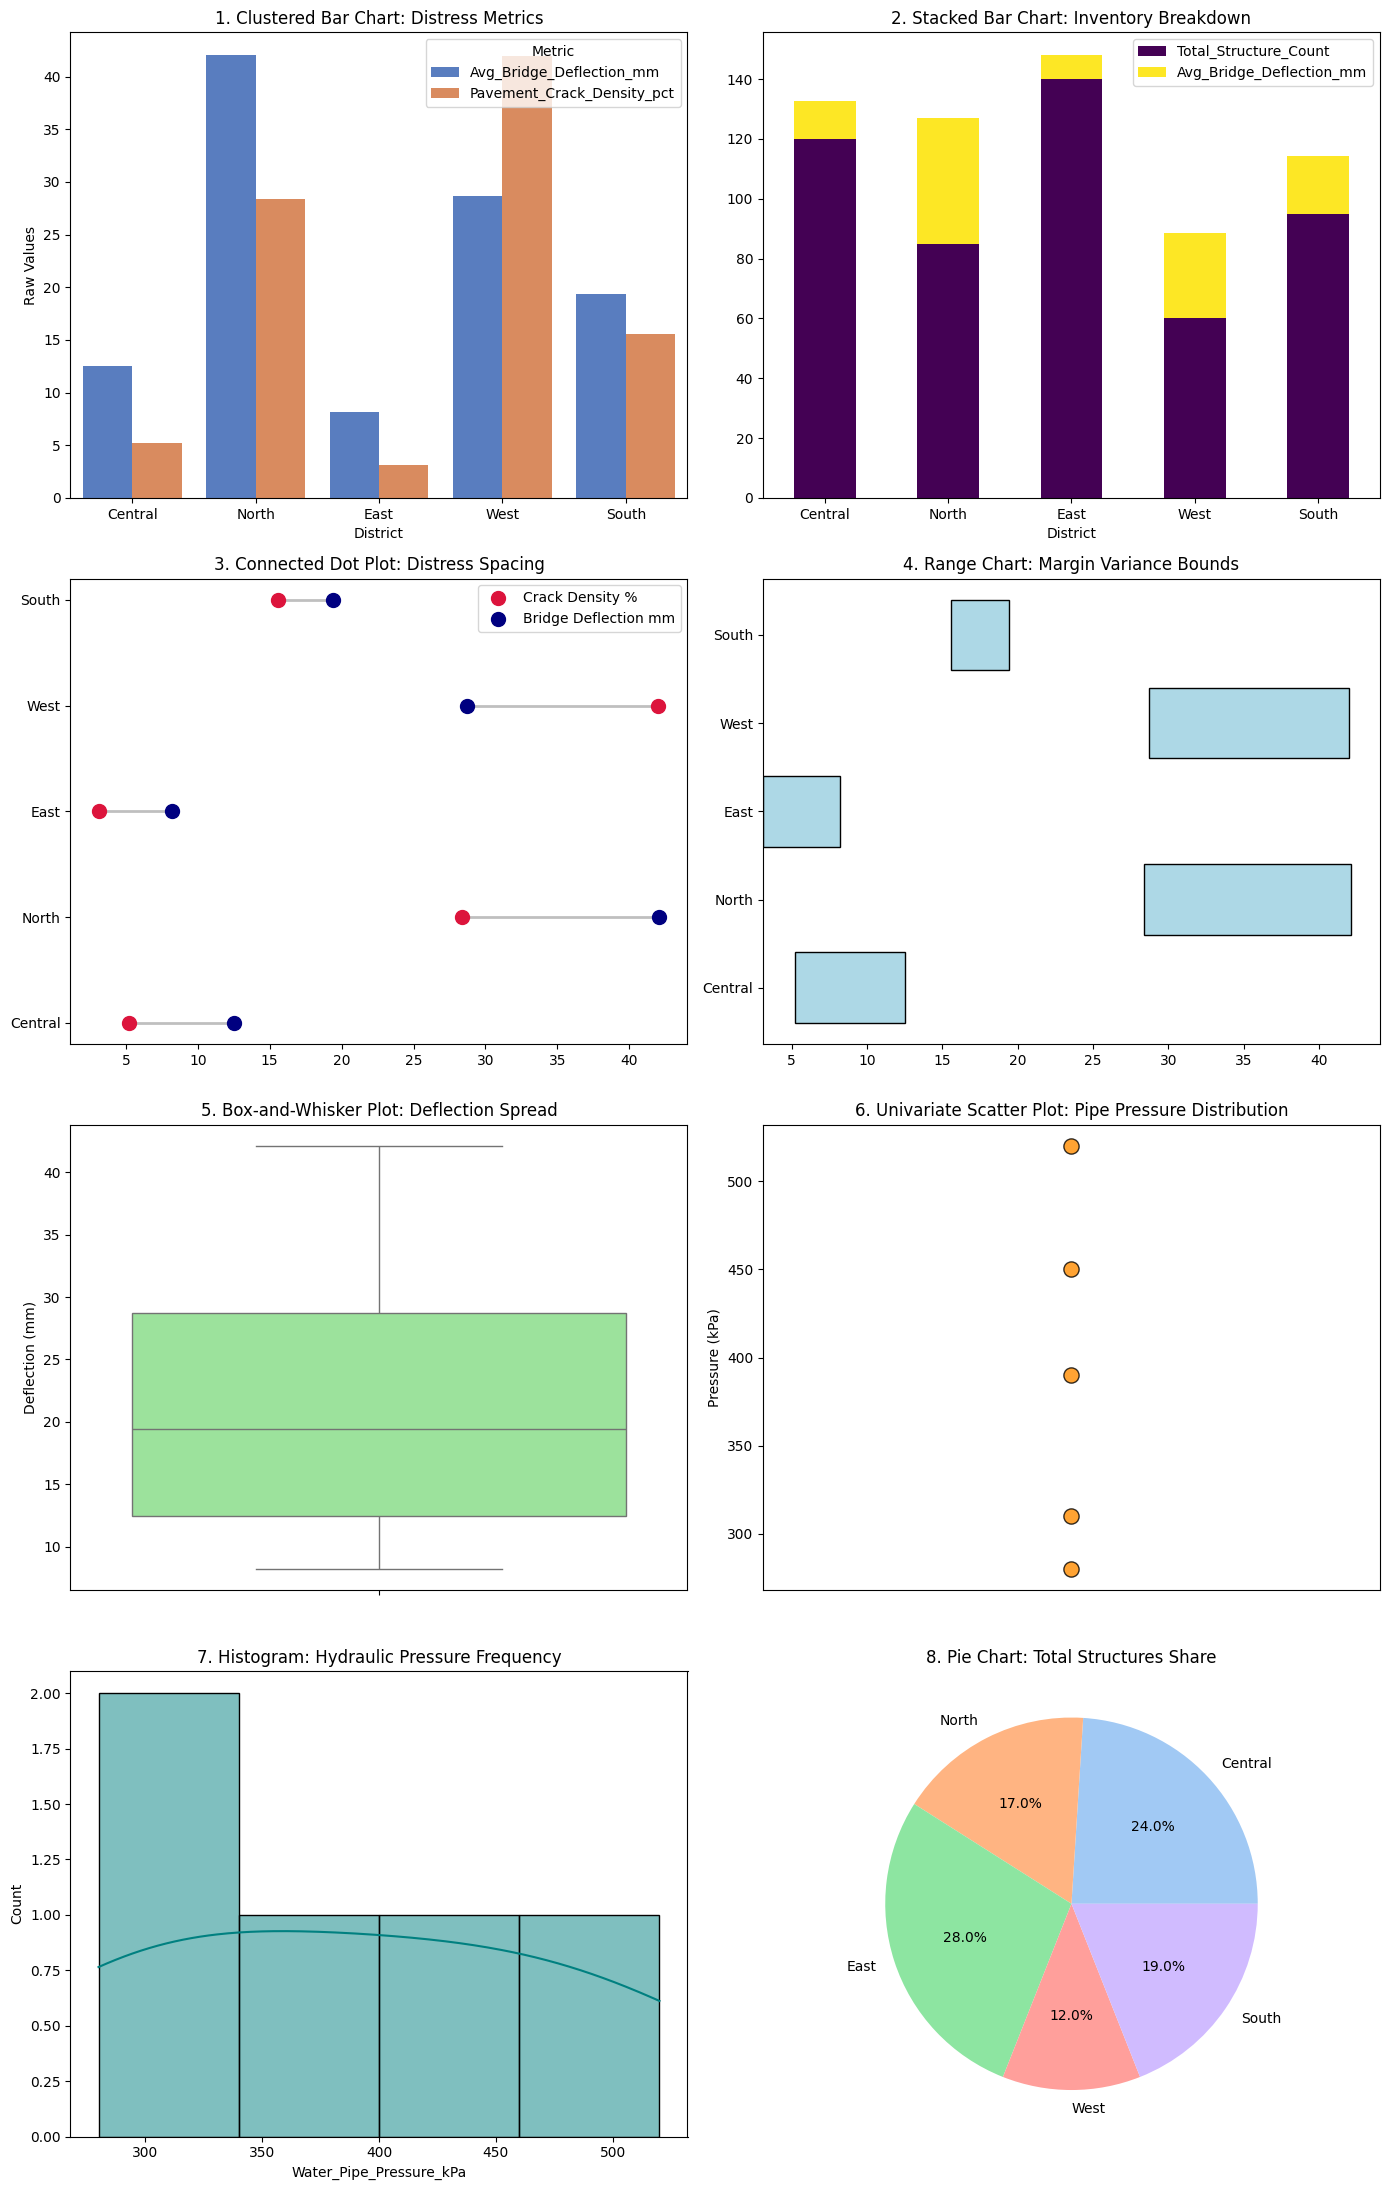

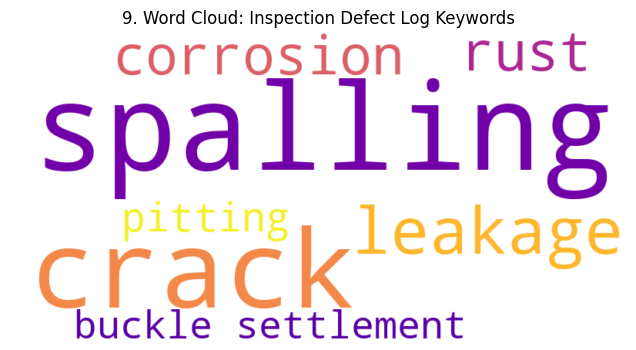

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from wordcloud import WordCloud

# =====================================================================
# STEP 1: Simulate Civil Case Study Dataset & Apply Normalisation
# =====================================================================
data = {
    "District": ["Central", "North", "East", "West", "South"],
    "Material_Type": ["Concrete", "Steel", "Concrete", "Masonry", "Steel"],
    "Avg_Bridge_Deflection_mm": [12.5, 42.1, 8.2, 28.7, 19.4],
    "Pavement_Crack_Density_pct": [5.2, 28.4, 3.1, 42.0, 15.6],
    "Water_Pipe_Pressure_kPa": [450.0, 310.0, 520.0, 280.0, 390.0],
    "Total_Structure_Count": [120, 85, 140, 60, 95],
    "Defect_Keywords": "crack spalling corrosion rust leakage crack spalling leakage corrosion spalling crack rust pitting spalling buckle settlement crack spalling leakage",
}

df = pd.DataFrame(data)

# Data Normalisation (Min-Max Scaling to 0-1) for cross-comparison
df_norm = df.copy()
numeric_cols = ["Avg_Bridge_Deflection_mm", "Pavement_Crack_Density_pct", "Water_Pipe_Pressure_kPa"]
for col in numeric_cols:
    df_norm[col] = (df[col] - df[col].min()) / (df[col].max() - df[col].min())

# Set up matplotlib figure grid for standard charts
fig, axes = plt.subplots(4, 2, figsize=(14, 22))
plt.style.use("default")

# 1. Clustered Bar Chart
df_melted = df.melt(id_vars="District", value_vars=["Avg_Bridge_Deflection_mm", "Pavement_Crack_Density_pct"],
                    var_name="Metric", value_name="Value")
sns.barplot(x="District", y="Value", hue="Metric", data=df_melted, ax=axes[0, 0], palette="muted")
axes[0, 0].set_title("1. Clustered Bar Chart: Distress Metrics")
axes[0, 0].set_ylabel("Raw Values")

# 2. Stacked Bar Chart
df.plot(x="District", y=["Total_Structure_Count", "Avg_Bridge_Deflection_mm"], kind="bar", stacked=True, ax=axes[0, 1], colormap="viridis")
axes[0, 1].set_title("2. Stacked Bar Chart: Inventory Breakdown")
axes[0, 1].tick_params(axis='x', rotation=0)

# 3. Connected Dot Plot (Dumbbell Plot)
axes[1, 0].hlines(y=df["District"], xmin=df["Pavement_Crack_Density_pct"], xmax=df["Avg_Bridge_Deflection_mm"], color="grey", alpha=0.5, linewidth=2)
axes[1, 0].scatter(df["Pavement_Crack_Density_pct"], df["District"], color="crimson", label="Crack Density %", s=100, zorder=3)
axes[1, 0].scatter(df["Avg_Bridge_Deflection_mm"], df["District"], color="navy", label="Bridge Deflection mm", s=100, zorder=3)
axes[1, 0].set_title("3. Connected Dot Plot: Distress Spacing")
axes[1, 0].legend()

# 4. Range Chart
axes[1, 1].barh(df["District"], df["Avg_Bridge_Deflection_mm" ] - df["Pavement_Crack_Density_pct"], left=df["Pavement_Crack_Density_pct"], color="lightblue", edgecolor="black")
axes[1, 1].set_title("4. Range Chart: Margin Variance Bounds")

# 5. Box-and-Whisker Plot
sns.boxplot(y=df["Avg_Bridge_Deflection_mm"], ax=axes[2, 0], color="lightgreen")
axes[2, 0].set_title("5. Box-and-Whisker Plot: Deflection Spread")
axes[2, 0].set_ylabel("Deflection (mm)")

# 6. Univariate Scatter Plot
axes[2, 1].scatter(np.zeros_like(df["Water_Pipe_Pressure_kPa"]), df["Water_Pipe_Pressure_kPa"], color="darkorange", s=120, alpha=0.8, edgecolor="black")
axes[2, 1].set_title("6. Univariate Scatter Plot: Pipe Pressure Distribution")
axes[2, 1].set_xticks([])
axes[2, 1].set_ylabel("Pressure (kPa)")

# 7. Histogram
sns.histplot(df["Water_Pipe_Pressure_kPa"], bins=4, kde=True, ax=axes[3, 0], color="teal")
axes[3, 0].set_title("7. Histogram: Hydraulic Pressure Frequency")

# 8. Pie Chart
axes[3, 1].pie(df["Total_Structure_Count"], labels=df["District"], autopct='%1.1f%%', colors=sns.color_palette("pastel"))
axes[3, 1].set_title("8. Pie Chart: Total Structures Share")

plt.tight_layout()
plt.show()

# Word Cloud Generation - Fixed by converting the Series data to a single string
keywords_str = " ".join(df["Defect_Keywords"].dropna().astype(str))
wordcloud = WordCloud(width=800, height=400, background_color="white", colormap="plasma").generate(keywords_str)
plt.figure(figsize=(8, 4))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("9. Word Cloud: Inspection Defect Log Keywords")
plt.show()

**Part 2 – Complex & Advanced Multidimensional Shapes**

This module isolates charts requiring advanced grid systems or distinct coordinate mappings: Bubble Charts, Radar Charts, Polar Charts, Treemaps, Waffle Charts, and Pictograms.

In [7]:
pip install plotly==5.14.1

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.3/15.3 MB 24.3 MB/s  0:00:00
  Attempting uninstall: plotly
    Found existing installation: plotly 5.24.1
    Uninstalling plotly-5.24.1:
      Successfully uninstalled plotly-5.24.1
Note: you may need to restart the kernel to use updated packages.


/usr/local/lib/python3.13/dist-packages/plotly/express/_core.py:1985: FutureWarning:

When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.



/tmp/ipykernel_16/984629802.py:97: UserWarning:

Glyph 129521 (\N{BRICK}) missing from font(s) DejaVu Sans.

/tmp/ipykernel_16/984629802.py:97: UserWarning:

Glyph 127968 (\N{HOUSE BUILDING}) missing from font(s) DejaVu Sans.

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning:

Glyph 129521 (\N{BRICK}) missing from font(s) DejaVu Sans.

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning:

Glyph 127968 (\N{HOUSE BUILDING}) missing from font(s) DejaVu Sans.



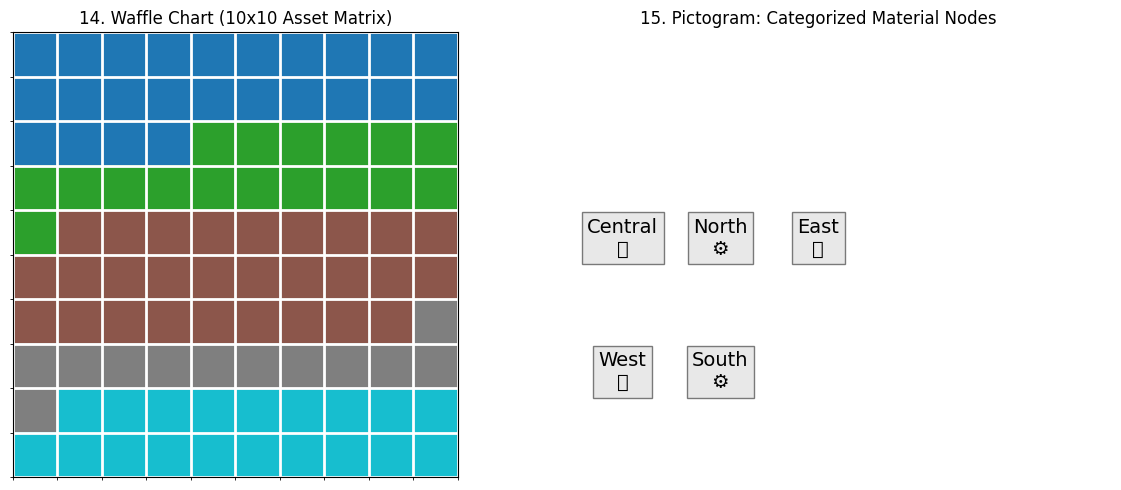

In [8]:
import plotly.express as px
import matplotlib.pyplot as plt
import numpy as np

data = {
    "District": ["Central", "North", "East", "West", "South"],
    "Material_Type": ["Concrete", "Steel", "Concrete", "Masonry", "Steel"],
    "Avg_Bridge_Deflection_mm": [12.5, 42.1, 8.2, 28.7, 19.4],
    "Pavement_Crack_Density_pct": [5.2, 28.4, 3.1, 42.0, 15.6],
    "Water_Pipe_Pressure_kPa": [450.0, 310.0, 520.0, 280.0, 390.0],
    "Total_Structure_Count": [120, 85, 140, 60, 95],
    "Defect_Keywords": "crack spalling corrosion rust leakage crack spalling leakage corrosion spalling crack rust pitting spalling buckle settlement crack spalling leakage",
}

df = pd.DataFrame(data)
# =====================================================================
# 10. Bubble Chart (4 Dimensions represented in 2D space)
# =====================================================================
# X=Deflection, Y=Crack Density, Size=Structure Volume, Color=Water Pressure
fig_bubble = px.scatter(
    df_norm, x="Avg_Bridge_Deflection_mm", y="Pavement_Crack_Density_pct", color="Water_Pipe_Pressure_kPa", size=df["Total_Structure_Count"],
    hover_name=df["District"], title="10. Bubble Chart: Normalized Metrics Mapping",
    labels={"Avg_Bridge_Deflection_mm": "Normalized Deflection", "Pavement_Crack_Density_pct": "Normalized Crack Density"}
)
fig_bubble.show()

# =====================================================================
# 11. Radar / Polar Charts
# =====================================================================
# Radar charts map categories along radiating angular lines inside a polar grid system
categories = ["Deflection", "Crack_Density", "Pipe_Pressure"]
# Close the loop by wrapping values back to the beginning index
radar_values = [df_norm.loc[0, "Avg_Bridge_Deflection_mm"],
                df_norm.loc[0, "Pavement_Crack_Density_pct"],
                df_norm.loc[0, "Water_Pipe_Pressure_kPa"]]

# Removed line_close=True to avoid the internal DataFrame.append() crash in older Plotly versions
fig_radar = px.line_polar(df_norm, r=radar_values, theta=categories, title="11. Radar Chart: Central District Metrics Profile")
fig_radar.update_traces(fill="toself")
fig_radar.show()

# Polar Bar Chart configuration
fig_polar = px.bar_polar(df, r="Avg_Bridge_Deflection_mm", theta="District", color="Material_Type", title="12. Polar Chart: Deflection vs Region Axes")
fig_polar.show()

# =====================================================================
# 13. Tree Map
# =====================================================================
# Maps structural volume split by engineering materials hierarchically
fig_tree = px.treemap(df, path=["Material_Type", "District"], values="Total_Structure_Count", title="13. Tree Map: Asset Breakdown by Material")
fig_tree.show()

# =====================================================================
# 14. Waffle Chart & 15. Character Pictogram (Simulated Grid Matrix)
# =====================================================================
# Generates a matrix display representing parts-to-whole assets visually.
total_blocks = 100
proportions = (df["Total_Structure_Count"] / df["Total_Structure_Count"].sum() * total_blocks).astype(int)

waffle_grid = []
for idx, district in enumerate(df["District"]):
    waffle_grid.extend([idx] * proportions[idx])

# Padding block matrix to preserve 10x10 dimensions if necessary
while len(waffle_grid) < total_blocks:
    waffle_grid.append(0)
waffle_matrix = np.array(waffle_grid).reshape(10, 10)

fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Plot Waffle Configuration (Fixed imshow parameter error and added clean grids manually)
axs[0].imshow(waffle_matrix, cmap="tab10")
axs[0].set_title("14. Waffle Chart (10x10 Asset Matrix)")
# Create grid lines using minor ticks for cleaner matrix cell borders
axs[0].set_xticks(np.arange(-.5, 10, 1), minor=True)
axs[0].set_yticks(np.arange(-.5, 10, 1), minor=True)
axs[0].grid(which='minor', color='w', linestyle='-', linewidth=2)
axs[0].set_xticks([])
axs[0].set_yticks([])

# Plot Pictogram Grid Matrix using Text Glyphs (🧱 Concrete vs ⚙️ Steel symbols)
axs[1].set_xlim(0, 6)
axs[1].set_ylim(0, 2)
marker_symbols = {"Concrete": "🧱", "Steel": "⚙️", "Masonry": "🏠"}
x_pos, y_pos = 1, 1

for index, row in df.iterrows():
    symbol = marker_symbols.get(row["Material_Type"], "❓")
    axs[1].text(x_pos, y_pos, f"{row['District']}\n{symbol}", fontsize=14, ha='center', bbox=dict(facecolor='lightgray', alpha=0.5))
    x_pos += 1
    if x_pos > 3:
        x_pos = 1
        y_pos -= 0.6

axs[1].set_title("15. Pictogram: Categorized Material Nodes")
axs[1].axis("off")
plt.tight_layout()
plt.show()

**Experiment 6: Multi-dimensional Data Visualization**

**Structural Health & Geotechnical Stability of Multi-Span Bridges.**

When dealing with more than two variables (e.g., combining structural stress, concrete temperature, geotechnical soil settlement, vibration frequency, and visual crack ratings), standard 2D plots fall short. To visualize these higher dimensions, we use specialized multidimensional techniques: Pair Plots, 3D Scatter Plots, Parallel Coordinates Plots, Heatmaps, and Principal Component Analysis (PCA) plots.

1. Correlation Heatmaps: Show how tightly linked parameters are. If you notice a high negative correlation between Vibration Frequency and Soil Settlement, it visually tells the engineer that structural degradation is causing changes in the structural resonance patterns.
2. Interactive 3D Scatter & Parallel Coordinates: Useful for identifying sensor operational boundaries. In the Parallel Coordinates Plot, you can trace paths directly; if a specific line trends high on the Settlement vertical bar and spikes high on Strain, you instantly isolate the specific structural outlier.
3. PCA Dimension Reduction: Condenses extensive multi-sensor matrices into a unified coordinate system. If the "High Risk" red points cluster far away from the "Low Risk" green points on the grid, it proves the telemetry parameters are highly effective markers for automated health monitoring models.


--- Multidimensional Dataset Snapshot ---
  Pier_ID  Concrete_Temp_C  Strain_Microstrain  Soil_Settlement_mm  \
0  Pier_1        26.983571          128.767250            0.994002   
1  Pier_2        23.808678          132.125687            0.586000   
2  Pier_3        27.738443           96.199135            4.166269   
3  Pier_4        32.115149          128.128879            4.932628   
4  Pier_5        23.329233          130.257537           13.971015   

   Vibration_Freq_Hz Risk_Condition  
0           3.839948       Low Risk  
1           4.698280  Moderate Risk  
2           3.345904       Low Risk  
3           4.086096       Low Risk  
4           4.296237      High Risk  




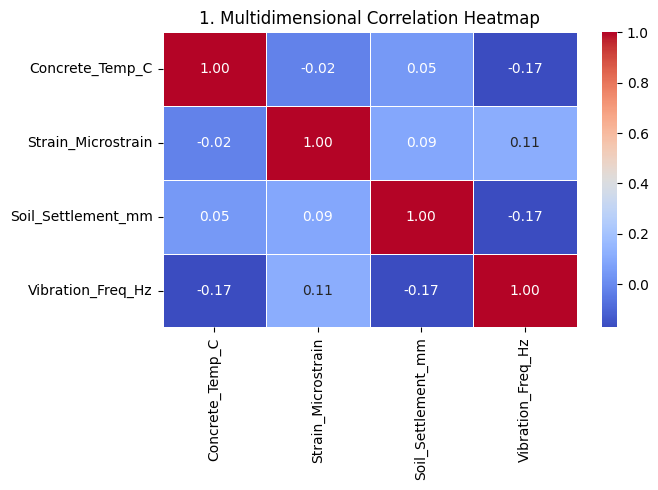

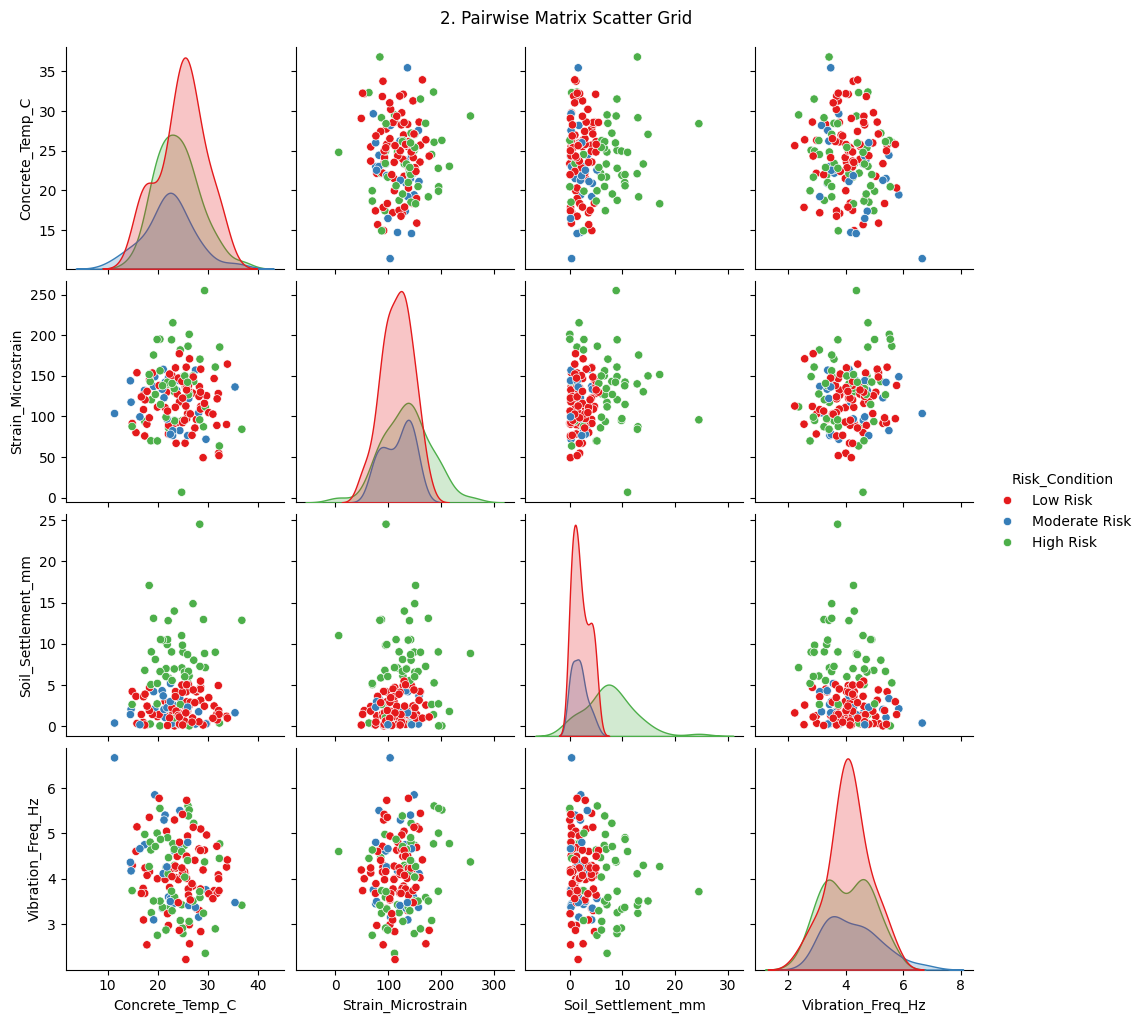

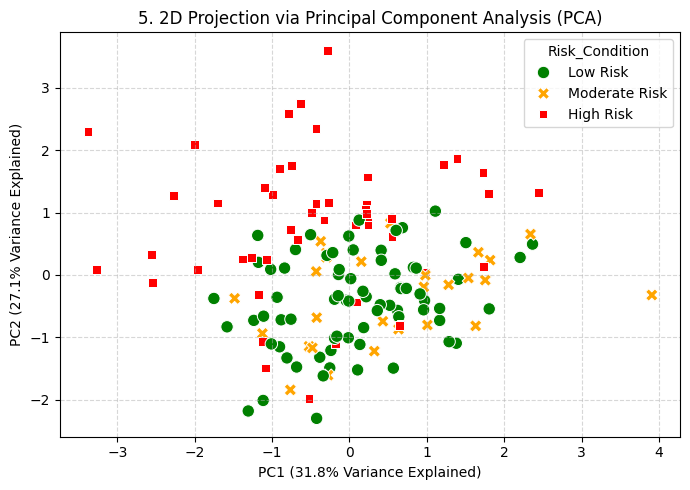

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# =====================================================================
# STEP 1: Simulate Multi-dimensional Civil Engineering Case Study Data
# =====================================================================
# Simulating continuous monitoring sensor streams from bridge piers/spans
np.random.seed(42)
n_samples = 150

data = {
    "Pier_ID": [f"Pier_{i}" for i in range(1, n_samples + 1)],
    "Concrete_Temp_C": np.random.normal(loc=24.5, scale=5.0, size=n_samples),
    "Strain_Microstrain": np.random.normal(loc=120.0, scale=35.0, size=n_samples),
    "Soil_Settlement_mm": np.random.exponential(scale=3.0, size=n_samples),
    "Vibration_Freq_Hz": np.random.normal(loc=4.2, scale=0.8, size=n_samples),
    # Categorical classification asset managers assign during walk-through inspections
    "Risk_Condition": np.random.choice(
        ["Low Risk", "Moderate Risk", "High Risk"],
        size=n_samples,
        p=[0.60, 0.30, 0.10],
    ),
}

# Explicitly injecting multidimensional correlations (e.g., high settlement + high strain = High Risk)
df = pd.DataFrame(data)
df.loc[
    (df["Soil_Settlement_mm"] > 5.5) | (df["Strain_Microstrain"] > 180),
    "Risk_Condition",
] = "High Risk"

print("--- Multidimensional Dataset Snapshot ---")
print(df.head())
print("\n" + "=" * 70 + "\n")

# Extract only the continuous numeric variables for dimensional processing
numeric_features = [
    "Concrete_Temp_C",
    "Strain_Microstrain",
    "Soil_Settlement_mm",
    "Vibration_Freq_Hz",
]

# =====================================================================
# VISUALISATION 1: Correlation Matrix Heatmap (Checking Interdependence)
# =====================================================================
# Displays how structural attributes scale relative to each other.
plt.figure(figsize=(7, 5))
corr_matrix = df[numeric_features].corr()
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("1. Multidimensional Correlation Heatmap")
plt.tight_layout()
plt.show()

# =====================================================================
# VISUALISATION 2: Pairwise Feature Matrix Grid (Pairplot)
# =====================================================================
# Generates a grid of scatter plots comparing every numeric pair,
# color-coded by the categorical engineering 'Risk_Condition'.
sns.pairplot(df, hue="Risk_Condition", palette="Set1", diag_kind="kde")
plt.suptitle("2. Pairwise Matrix Scatter Grid", y=1.02)
plt.show()

# =====================================================================
# VISUALISATION 3: Interactive 3D Scatter Plot (4 Dimensions)
# =====================================================================
# Dimension 1: X-axis | Dimension 2: Y-axis | Dimension 3: Z-axis | Dimension 4: Color Map
fig_3d = px.scatter_3d(
    df,
    x="Strain_Microstrain",
    y="Soil_Settlement_mm",
    z="Vibration_Freq_Hz",
    color="Risk_Condition",
    symbol="Risk_Condition",
    title="3. Interactive 4D Scatter Space (Strain vs Settlement vs Freq vs Risk)",
    color_discrete_map={
        "Low Risk": "green",
        "Moderate Risk": "orange",
        "High Risk": "red",
    },
)
fig_3d.update_layout(scene=dict(xaxis_title="Strain", yaxis_title="Settlement (mm)", zaxis_title="Freq (Hz)"))
fig_3d.show()

# =====================================================================
# VISUALISATION 4: Parallel Coordinates Plot (Hyper-Dimensional Scaling)
# =====================================================================
# Excellent for tracing anomalies across high-dimensional parameter configurations.
# Convert the text risks to numeric codes for plotting compatibility
df["Risk_Code"] = df["Risk_Condition"].astype("category").cat.codes

fig_parallel = px.parallel_coordinates(
    df,
    dimensions=numeric_features,
    color="Risk_Code",
    title="4. Parallel Coordinates Configuration Pathing",
    color_continuous_scale=px.colors.diverging.Tealrose,
)
fig_parallel.show()

# =====================================================================
# VISUALISATION 5: Principal Component Analysis (PCA) Dimension Reduction
# =====================================================================
# Condenses 4 numeric dimensions into 2 orthogonal axes (PC1 & PC2)
# to project structural behavior on a flattened map.
X = df[numeric_features]
X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

df_pca = pd.DataFrame(data=X_pca, columns=["PC1", "PC2"])
df_pca["Risk_Condition"] = df["Risk_Condition"]

plt.figure(figsize=(7, 5))
sns.scatterplot(
    x="PC1",
    y="PC2",
    hue="Risk_Condition",
    style="Risk_Condition",
    data=df_pca,
    palette={"Low Risk": "green", "Moderate Risk": "orange", "High Risk": "red"},
    s=80,
)
plt.title("5. 2D Projection via Principal Component Analysis (PCA)")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance Explained)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance Explained)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()



**Experiment 7: Graph data visualization**
case study involving relational networks (such as traffic flow routes, structural load paths, water supply networks, or project management critical path methods), standard 2D plots are inadequate. True Graph Data Visualization uses Nodes (representing joints, stations, or intersections) and Edges (representing beams, pipes, roads, or dependencies).
Here is the complete Python script using networkx and matplotlib to construct and visualize a Smart City Infrastructure & Supply Dependency Network.



1. Force-Directed Spatial Mapping: The spring_layout dynamically spaces components. Nodes that share high transmission loads group together, while disconnected assets drift naturally to the outer margins of the canvas.
2. Dynamic Width Sizing: Setting width=edge_weights visually changes pipeline scaling. A pipeline operating at 120 units displays thick and pronounced, while a localized trunk line scaling

In [10]:
pip install networkx matplotlib numpy pandas


Note: you may need to restart the kernel to use updated packages.


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning:

Glyph 128167 (\N{DROPLET}) missing from font(s) DejaVu Sans.

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning:

Glyph 9981 (\N{FUEL PUMP}) missing from font(s) DejaVu Sans.

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning:

Glyph 128268 (\N{ELECTRIC PLUG}) missing from font(s) DejaVu Sans.

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning:

Glyph 128678 (\N{VERTICAL TRAFFIC LIGHT}) missing from font(s) DejaVu Sans.

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning:

Glyph 127968 (\N{HOUSE BUILDING}) missing from font(s) DejaVu Sans.

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning:

Glyph 127981 (\N{FACTORY}) missing from font(s) DejaVu Sans.

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning:

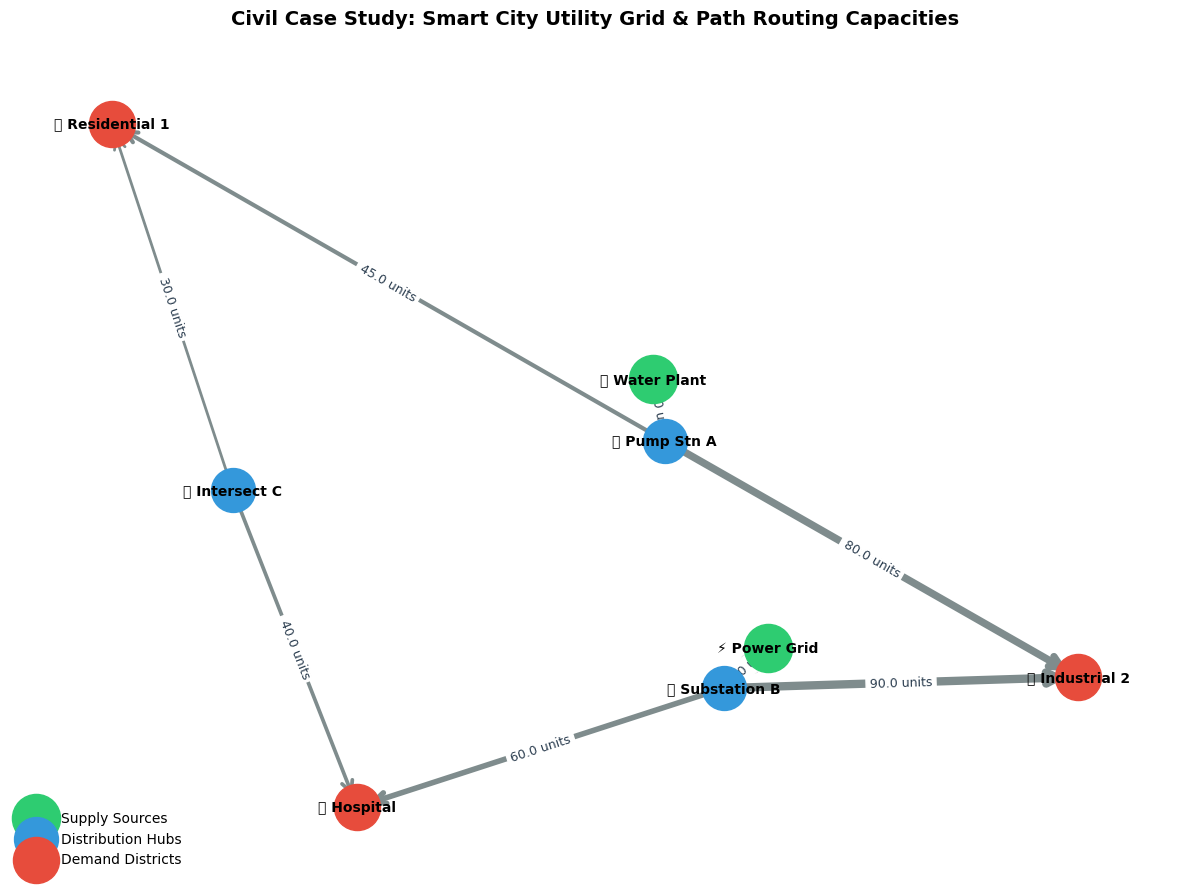

In [11]:
import matplotlib.pyplot as plt
import networkx as nx

# =====================================================================
# STEP 1: Initialize the Graph and Define Civil Infrastructure Nodes
# =====================================================================
# Creating a Directional Graph (DiGraph) to model resource routing flow
G = nx.DiGraph()

# Define Infrastructure Nodes categorized by asset group types
nodes_infrastructure = {
    # Supply Sources / Generation
    "Water_Treatment_Plant": {"type": "Source", "label": "💧 Water Plant"},
    "Power_Grid_Station": {"type": "Source", "label": "⚡ Power Grid"},

    # Distribution Hubs / Substations
    "Pumping_Station_A": {"type": "Hub", "label": "⛽ Pump Stn A"},
    "Electrical_Substation_B": {"type": "Hub", "label": "🔌 Substation B"},
    "Traffic_Intersection_C": {"type": "Hub", "label": "🚦 Intersect C"},

    # End-User Demand Sectors
    "Residential_District_1": {"type": "Demand", "label": "🏠 Residential 1"},
    "Industrial_Zone_2": {"type": "Demand", "label": "🏭 Industrial 2"},
    "Smart_City_Hospital": {"type": "Demand", "label": "🏥 Hospital"},
}

# Add nodes with their respective feature attributes to the network object
for node, attrs in nodes_infrastructure.items():
    G.add_node(node, **attrs)

# =====================================================================
# STEP 2: Establish Network Edges & Engineering Capacities (Weights)
# =====================================================================
# Edges represent conduits (Pipes, Transmission Lines, Highways).
# 'weight' corresponds to pipeline or utility grid throughput capacity.
edges_conduits = [
    ("Water_Treatment_Plant", "Pumping_Station_A", 95.0),
    ("Power_Grid_Station", "Electrical_Substation_B", 120.0),

    ("Pumping_Station_A", "Residential_District_1", 45.0),
    ("Pumping_Station_A", "Industrial_Zone_2", 80.0),

    ("Electrical_Substation_B", "Industrial_Zone_2", 90.0),
    ("Electrical_Substation_B", "Smart_City_Hospital", 60.0),

    ("Traffic_Intersection_C", "Residential_District_1", 30.0),
    ("Traffic_Intersection_C", "Smart_City_Hospital", 40.0),
]

for u, v, weight in edges_conduits:
    G.add_edge(u, v, weight=weight)

# =====================================================================
# STEP 3: Structural Layout Calculation & Grouping Formatting
# =====================================================================
plt.figure(figsize=(12, 9))

# Calculate node coordinates using a spring layout model (Force-directed mapping)
pos = nx.spring_layout(G, seed=42, k=1.5)

# Segregate nodes into functional subsets for distinct coloring profiles
source_nodes = [n for n, attr in G.nodes(data=True) if attr.get("type") == "Source"]
hub_nodes = [n for n, attr in G.nodes(data=True) if attr.get("type") == "Hub"]
demand_nodes = [n for n, attr in G.nodes(data=True) if attr.get("type") == "Demand"]

# Draw Nodes with explicit size and color configurations
nx.draw_networkx_nodes(G, pos, nodelist=source_nodes, node_color="#2ecc71", node_size=1200, label="Supply Sources")
nx.draw_networkx_nodes(G, pos, nodelist=hub_nodes, node_color="#3498db", node_size=1000, label="Distribution Hubs")
nx.draw_networkx_nodes(G, pos, nodelist=demand_nodes, node_color="#e74c3c", node_size=1100, label="Demand Districts")

# =====================================================================
# STEP 4: Render Paths and Capacity Metrics (Weights)
# =====================================================================
# Extract edge weights to dynamically adjust connection line thicknesses
edge_weights = [G[u][v]['weight'] / 15.0 for u, v in G.edges()]

# Draw directional path arrows
nx.draw_networkx_edges(G, pos, width=edge_weights, edge_color="#7f8c8d", arrowsize=20, arrowstyle="->")

# Map descriptive structural text tags onto nodes
node_labels = nx.get_node_attributes(G, 'label')
nx.draw_networkx_labels(G, pos, labels=node_labels, font_size=10, font_weight="bold", font_family="sans-serif")

# Overlay structural throughput numbers directly onto connection edges
edge_labels = {(u, v): f"{d['weight']} units" for u, v, d in G.edges(data=True)}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=9, font_color="#2c3e50")

# Finalize layout decorations
plt.title("Civil Case Study: Smart City Utility Grid & Path Routing Capacities", fontsize=14, fontweight="bold", pad=20)
plt.legend(scatterpoints=1, loc="lower left", frameon=True, facecolor="white", edgecolor="none")
plt.axis("off")
plt.tight_layout()
plt.show()
